In [6]:
import pandas as pd

# Читаем сохранённый файл с подготовленными данными, делая первый столбец индексом DataFrame
df_eda = pd.read_csv('wells_prepared_data.csv', sep=';', index_col=0, encoding='utf-8-sig')

# Проверяем результат
print("Размерность таблицы:", df_eda.shape)

Размерность таблицы: (39, 15)


In [7]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39 entries, A to EW
Data columns (total 15 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Heff                                          39 non-null     float64
 1   X                                             39 non-null     float64
 2   Y                                             39 non-null     float64
 3   dT_Ju1                                        39 non-null     float64
 4   Grid_Y                                        39 non-null     float64
 5   Ju1_a14b4_2nd_derivative_mean                 39 non-null     float64
 6   Ju1_a14b4_2nd_derivative_sum_positive         39 non-null     float64
 7   Ju1_a14b4_amp_weighted_cos_phase_rms_average  39 non-null     float64
 8   Ju1_a14b4_amp_weighted_phase_sum_abs_diff     39 non-null     float64
 9   Ju1_a14b4_average_freq_sum_abs_diff           39 non-null     float64
 1

In [ ]:
# Разделим датасет на обучающую и тестовую выборки.
# Из-за малого объема выборки (39 точек) отдадим в тест 25% данных (~10 скважин).

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Исключаем целевую переменную и координаты
X_raw = df_eda.drop(columns=['Heff', 'X', 'Y'], errors='ignore')
y = df_eda['Heff']

# Разделяем данные на трейн и тест случайным образом (75% на 25%)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.25, random_state=1101
)

# Применяем нормировку с помощью StandardScaler
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(scaler.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)

print(f"Размер случайного трейна: {X_train.shape}")
print(f"Размер случайного теста: {X_test.shape}")


Размер случайного трейна: (29, 12)
Размер случайного теста: (10, 12)


In [12]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
dT_Ju1,29.0,5.704249e-16,1.0177,-1.296243,-0.733018,-0.337061,0.650327,2.441205
Grid_Y,29.0,-4.174199e-14,1.0177,-2.792155,-0.339502,0.421525,0.726269,0.946042
Ju1_a14b4_2nd_derivative_mean,29.0,1.531342e-17,1.0177,-2.022553,-0.598321,-0.118995,0.582221,2.671809
Ju1_a14b4_2nd_derivative_sum_positive,29.0,-7.924695e-16,1.0177,-1.513762,-0.670647,-0.270793,0.818868,2.527647
Ju1_a14b4_amp_weighted_cos_phase_rms_average,29.0,3.426378e-16,1.0177,-2.330717,-0.509466,0.183751,0.680399,1.560672
Ju1_a14b4_amp_weighted_phase_sum_abs_diff,29.0,2.603282e-16,1.0177,-2.014723,-0.829410,0.383773,0.627061,1.563554
Ju1_a14b4_average_freq_sum_abs_diff,29.0,-6.340713e-17,1.0177,-1.792953,-0.688345,-0.041972,0.456362,2.229721
Ju1_a14b4_derivative_inst_amp_mean,29.0,2.679849e-16,1.0177,-1.916558,-0.670479,-0.341575,0.914416,2.021916
Ju1_a14b4_derivative_inst_amp_sum_negative,29.0,-2.488431e-16,1.0177,-2.194796,-0.659337,-0.342388,0.508287,2.410049
Ju1_a14b4_filt_15_20_25_30_mean,29.0,-6.891039e-17,1.0177,-1.626509,-0.820478,-0.208857,0.660556,2.020950


In [13]:
X_test.describe().T

,count,mean,std,min,25%,50%,75%,max
dT_Ju1,10.0,-0.105232,1.096264,-1.593163,-0.678759,-0.410643,0.201181,1.904205
Grid_Y,10.0,0.074678,0.966722,-1.973501,0.105870,0.482671,0.657016,0.906145
Ju1_a14b4_2nd_derivative_mean,10.0,-0.154854,1.086103,-1.694163,-1.083018,-0.128357,0.823649,1.303066
Ju1_a14b4_2nd_derivative_sum_positive,10.0,0.054980,0.916987,-1.391646,-0.538872,0.048556,0.431891,1.488425
Ju1_a14b4_amp_weighted_cos_phase_rms_average,10.0,-0.229990,1.611066,-2.265655,-1.614456,-0.590297,1.079258,2.498323
Ju1_a14b4_amp_weighted_phase_sum_abs_diff,10.0,-0.128711,1.276694,-1.767851,-1.073522,-0.565067,0.908378,2.023555
Ju1_a14b4_average_freq_sum_abs_diff,10.0,-0.150509,1.120599,-1.715563,-1.033925,-0.138181,0.509157,1.910629
Ju1_a14b4_derivative_inst_amp_mean,10.0,0.081037,0.854330,-1.326328,-0.484983,0.245203,0.810242,0.947240
Ju1_a14b4_derivative_inst_amp_sum_negative,10.0,-0.283922,1.003937,-1.879136,-0.774308,-0.578080,0.332211,1.638341
Ju1_a14b4_filt_15_20_25_30_mean,10.0,-0.305963,0.951066,-1.685533,-0.862566,-0.423904,0.316113,1.064857


In [ ]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from scipy.stats import pearsonr

# --- 1. Подготовка структур для сбора результатов ---
models_results = {}

# Вспомогательная функция для оценки и записи расширенных результатов
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    # Предсказания
    pred_train = model.predict(X_tr)
    pred_test = model.predict(X_te)
    
    # Расчет векторов ошибок (разница между фактом и прогнозом)
    errors_train = y_tr - pred_train
    errors_test = y_te - pred_test
    
    # Метрики качества
    r_tr = root_mean_squared_error(y_tr, pred_train)
    r_te = root_mean_squared_error(y_te, pred_test)
    mae_tr = mean_absolute_error(y_tr, pred_train)
    mae_te = mean_absolute_error(y_te, pred_test)
    
    # Стандартное отклонение ошибок (разброс предсказаний вокруг факта)
    std_err_tr = np.std(errors_train)
    std_err_te = np.std(errors_test)

    try:
        corr_tr, _ = pearsonr(y_tr, pred_train)
    except:
        corr_tr = np.nan
        
    try:
        corr_te, _ = pearsonr(y_te, pred_test)
    except:
        corr_te = np.nan
    
    # Сбор результатов в словарь
    models_results[name] = {
        'Train RMSE': round(r_tr, 2),
        'Test RMSE': round(r_te, 2),
        'Train Corr': round(corr_tr, 3),
        'Test Corr': round(corr_te, 3), 
        'Train MAE': round(mae_tr, 2),
        'Test MAE': round(mae_te, 2),
        'Train Std Err': round(std_err_tr, 2),
        'Test Std Err': round(std_err_te, 2),
        'Train Heff Range': f"{y_tr.min():.1f} .. {y_tr.max():.1f}",
        'Test Heff Range': f"{y_te.min():.1f} .. {y_te.max():.1f}"
    }
    print(f"[{name}] Метрики рассчитаны.")

# --- 2. Обучение моделей с перебором гиперпараметров через GridSearchCV ---

# 1. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate_model('Linear Regression', lr, X_train, y_train, X_test, y_test)

# Сетка альфа для регуляризации
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

# 2. Ridge Regression
ridge_grid = GridSearchCV(Ridge(random_state=1101), {'alpha': alphas}, cv=3, scoring='neg_mean_absolute_error')
ridge_grid.fit(X_train, y_train)
evaluate_model('Ridge Regression', ridge_grid.best_estimator_, X_train, y_train, X_test, y_test)

# 3. Lasso Regression
lasso_grid = GridSearchCV(Lasso(max_iter=10000, random_state=1101), {'alpha': alphas}, cv=3, scoring='neg_mean_absolute_error')
lasso_grid.fit(X_train, y_train)
evaluate_model('Lasso Regression', lasso_grid.best_estimator_, X_train, y_train, X_test, y_test)

# 4. ElasticNet
elastic_param_grid = {'alpha': alphas, 'l1_ratio': [0.2, 0.5, 0.7]}
elastic_grid = GridSearchCV(ElasticNet(max_iter=10000, random_state=1101), elastic_param_grid, cv=3, scoring='neg_mean_absolute_error')
elastic_grid.fit(X_train, y_train)
evaluate_model('ElasticNet', elastic_grid.best_estimator_, X_train, y_train, X_test, y_test)

# 5. Polynomial Regression
poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures()),
    ('lr', LinearRegression())
])
poly_param_grid = {'poly__degree': [1, 2, 3], 'poly__interaction_only': [True, False]}
poly_grid = GridSearchCV(poly_pipeline, poly_param_grid, cv=3, scoring='neg_mean_absolute_error')
poly_grid.fit(X_train, y_train)
evaluate_model('Polynomial Regression', poly_grid.best_estimator_, X_train, y_train, X_test, y_test)

# --- 3. Вывод расширенной итоговой таблицы ---
df_results = pd.DataFrame(models_results).T
df_results

[Linear Regression] Метрики рассчитаны.
[Ridge Regression] Метрики рассчитаны.
[Lasso Regression] Метрики рассчитаны.
[ElasticNet] Метрики рассчитаны.
[Polynomial Regression] Метрики рассчитаны.


,Train RMSE,Test RMSE,Train Corr,Test Corr,Train MAE,Test MAE,Train Std Err,Test Std Err,Train Heff Range,Test Heff Range
Linear Regression,1.46,2.05,0.849,0.785,1.06,1.76,1.46,1.46,0.0 .. 9.7,3.3 .. 8.1
Ridge Regression,1.66,1.53,0.811,0.802,1.21,1.35,1.66,1.12,0.0 .. 9.7,3.3 .. 8.1
Lasso Regression,1.53,1.57,0.835,0.807,1.12,1.41,1.53,1.11,0.0 .. 9.7,3.3 .. 8.1
ElasticNet,1.52,1.74,0.839,0.8,1.12,1.55,1.52,1.23,0.0 .. 9.7,3.3 .. 8.1
Polynomial Regression,1.46,2.05,0.849,0.785,1.06,1.76,1.46,1.46,0.0 .. 9.7,3.3 .. 8.1


In [25]:
lasso_grid.best_estimator_

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",1101
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [32]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
warnings.filterwarnings('ignore')

from functions_read_data import read_hr_slice

def build_prediction_map(best_lasso_model, trained_scaler, feature_columns, data_slices_dir='./DATA_SLICES/', output_txt='predicted_heff_map.txt'):
    """
    Применяет обученную модель Lasso ко всей площади сейсмического куба и генерирует файл карты предсказания Heff.
        :param best_lasso_model: Обученный объект Lasso из GridSearchCV (lasso_grid.best_estimator_)
        :param trained_scaler: Объект StandardScaler, который обучался на X_train_raw
        :param feature_columns: Список названий признаков (колонок), которые ожидает модель
        :param data_slices_dir: Папка с исходными 60 файлами сейсмики
        :param output_txt: Имя файла для сохранения результата в формате HR
    """
    print("Сбор сейсмической сетки координат и атрибутов...")
    
    # Сначала прочитаем первый файл, чтобы инициализировать базовую сетку координат X и Y
    first_feature = feature_columns[0]
    first_file_path = glob.glob(os.path.join(data_slices_dir, f"{first_feature}.*"))
    
    if not first_file_path:
        raise FileNotFoundError(f"Не найден базовый файл для признака {first_feature} в папке {data_slices_dir}")
        
    # Загружаем базовую сетку (используем функцию read_hr_slice)
    df_map, _ = read_hr_slice(first_file_path[0])
    df_map.rename(columns={'Value': first_feature}, inplace=True)
    print(f"   --> Загружен атрибут для карты: {first_feature}")
    
    # Последовательно подгружаем остальные нужные признаки методом merge по координатам X и Y
    for col in feature_columns[1:]:
        file_path = glob.glob(os.path.join(data_slices_dir, f"{col}.*"))
        if file_path:
            df_slice, _ = read_hr_slice(file_path[0])
            df_slice.rename(columns={'Value': col}, inplace=True)
            # Объединяем строго по координатам
            df_map = pd.merge(df_map, df_slice, on=['X', 'Y'], how='left')
            print(f"   --> Добавлен атрибут для карты: {col}")
        else:
            print(f"   [Ошибка]: Файл для признака {col} не найден. Карта может быть некорректной.")

    print(f"\nРазмер площадной матрицы данных: {df_map.shape[0]} точек сетки.")
    
    # Шаг 2: Выделяем матрицу признаков и обрабатываем пропуски
    X_map_raw = df_map[feature_columns].copy()
    
    # Для точек вне контура сейсмики или на границах могут быть NaN. 
    # Запомним маску валидных точек, где есть абсолютно все признаки для прогноза
    valid_mask = X_map_raw.notna().all(axis=1)
    
    # Создаем массив под прогноз, по умолчанию заполненный Null Value для HR (-1.0000e+36)
    heff_predictions = np.full(len(df_map), -1.0000e+36)
    
    if not valid_mask.any():
        print("Ошибка: Нет ни одной точки на карте, где пересекаются все необходимые признаки!")
        return

    print("\nШаг 2: Нормализация площадных данных и расчет прогноза Heff...")
    # Берем только валидные строки для прогноза
    X_valid_raw = X_map_raw[valid_mask]
    
    # МАСШТАБИРОВАНИЕ: Используем сохраненный скважинный скалер (ТОЛЬКО transform!)
    X_valid_scaled = trained_scaler.transform(X_valid_raw)
    
    # ПРОГНОЗ: Применяем лучшую Lasso модель
    valid_preds = best_lasso_model.predict(X_valid_scaled)
    
    # Записываем предсказанные значения обратно в общий массив
    heff_predictions[valid_mask] = valid_preds
    
    # Добавляем прогноз в итоговый датафрейм карты
    df_map['Heff_Pred'] = heff_predictions

    # Шаг 3: Экспорт результата в формате HampsonRussell
    print(f"\nШаг 3: Экспорт карты в файл в формате HampsonRussell: {output_txt}")
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Записываем стандартную структуру заголовка HR
        f.write("#{SLICE}{VERSION 1.1}{2D DATA} Output File From Python Machine Learning\n")
        f.write("#{HEADER}\n")
        f.write("<Slice Name>                    <2D/3D>  <Category>  <Domain>  <Domain Unit>  <Null Value>  <Time Component>  <Amp Type>          <Amp Unit>  <Source Volume>  \n")
        f.write(" Predicted_Heff_Lasso           3D       P           Unset     _              -1.0000e+36   Unset             ML_Prediction       _           _               \n")
        f.write("    <Description>\n")
        f.write(" \n")
        f.write("    <\\Description>\n")
        f.write("#{BODY}\n")
        f.write("<X>             <Y>             <Value: Predicted_Heff_Lasso>\n")
        
        # Записываем сами данные матрицы построчно (X, Y, Прогноз)
        # Ограничиваем количество знаков после запятой для экономии места
        df_map[['X', 'Y', 'Heff_Pred']].to_csv(f, sep='\t', index=False, header=False, float_format='%.4f')
        
    print("Экспорт завершен успешно!")

    # Шаг 4: Визуализация результирующей карты прямо в Python
    print("\nШаг 4: Отрисовка финальной прогнозной карты (> 0 м, изолинии 1 м, скважины)...")
    
    # Фильтруем данные: убираем пустые значения HR и оставляем строго толщины больше 0 метров
    df_valid_map = df_map[(df_map['Heff_Pred'] != -1.0000e+36) & (df_map['Heff_Pred'] > 0)]
    
    if df_valid_map.empty:
        print("Ошибка: После фильтрации (> 0 м) не осталось данных для отрисовки карты!")
        return

    plt.figure(figsize=(14, 12))
    sns.set_theme(style="white") # Чистый белый фон без лишних сеток, как на геологических планшетах

    # 1. Строим сглаженное цветовое поле (цветовая заливка толщин)
    contour_fill = plt.tricontourf(
        df_valid_map['X'], 
        df_valid_map['Y'], 
        df_valid_map['Heff_Pred'], 
        levels=100, 
        cmap='YlOrRd' # Палитра от желтого к красному
    )
    
    # Добавляем световую шкалу толщин
    cbar = plt.colorbar(contour_fill, shrink=0.8)
    cbar.set_label('Прогноз эффективной толщины Heff (м)', fontsize=12, labelpad=10, weight='bold')

    # 2. Расчет и отрисовка изолиний с шагом ровно 1 метр
    # Находим диапазон округленных значений, чтобы шаг лег ровно на целые метры
    min_pred = math.floor(df_valid_map['Heff_Pred'].min())
    max_pred = math.ceil(df_valid_map['Heff_Pred'].max())
    
    # Создаем массив уровней для изолиний от min до max с шагом 1.0
    levels_1m = np.arange(min_pred, max_pred + 1, 1.0)
    # Исключаем уровень 0, если он случайно попал, так как мы смотрим строго > 0
    levels_1m = levels_1m[levels_1m > 0] 

    if len(levels_1m) > 0:
        contour_lines = plt.tricontour(
            df_valid_map['X'], 
            df_valid_map['Y'], 
            df_valid_map['Heff_Pred'], 
            levels=levels_1m, 
            colors='black',      # Строгие черные изолинии
            linewidths=0.8,      # Тонкие линии
            alpha=0.6            # Полупрозрачные, чтобы не перекрывать цвета
        )
        # Добавляем цифровые подписи значений прямо на сами изолинии
        plt.clabel(contour_lines, inline=True, fmt='%.0f м', fontsize=9, colors='black')

    # 3. Наносим точки скважин из вашего исходного df_eda поверх прогнозной карты
    # Предполагаем, что df_eda доступен глобально или передан в функцию (лучше передать в аргументы)
    if 'df_eda' in globals() or 'df_restored' in globals():
        # Берем таблицу, которая активна в вашем скрипте
        df_wells_to_plot = globals().get('df_eda', globals().get('df_restored'))
        
        # Наносим скважины в виде контрастных черных кружков с белой окантовкой
        plt.scatter(
            df_wells_to_plot['X'], 
            df_wells_to_plot['Y'], 
            color='black', 
            marker='o', 
            s=80, 
            edgecolors='white', 
            linewidths=1.8,
            label='Скважины (ML)',
            zorder=5 # Гарантирует, что скважины будут лежать поверх всех заливок и линий
        )
        
        # Подписываем названия скважин (используем индекс WellName или колонку)
        for idx, row in df_wells_to_plot.iterrows():
            # Если WellName — это индекс, берем его имя, иначе берем из колонки
            well_name = idx if df_wells_to_plot.index.name == 'WellName' else row.get('WellName', 'Well')
            
            plt.text(
                row['X'], 
                row['Y'] + 40,  # Делаем небольшой сдвиг по оси Y вверх, чтобы надпись не налегала на точку скважины
                f"{well_name}", 
                fontsize=9, 
                weight='bold', 
                color='black',
                va='bottom', 
                ha='center',
                zorder=6,
                # Добавляем легкую белую подложку под текст, чтобы названия скважин читались на темном (красном) фоне карты
                bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none')
            )
        plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='gray')

    # 4. Оформление осей и заголовков
    plt.title("Прогнозная карта эффективных толщин Heff\nМодель: Lasso Regression", fontsize=12, weight='bold', pad=15)
    plt.xlabel("Координата X (м)", fontsize=10)
    plt.ylabel("Координата Y (м)", fontsize=10)
    
    # Строгое сохранение пропорций 1:1 по осям
    plt.gca().set_aspect('equal', adjustable='box')
    
    # Сохраняем картинку карты в высоком разрешении
    plt.tight_layout()
    output_img_path = 'predicted_heff_map_contour.png'
    plt.savefig(output_img_path, dpi=300, bbox_inches='tight')
    
    print(f"Карта с изолиниями и скважинами успешно сохранена в '{output_img_path}'")
    plt.show()


Сбор сейсмической сетки координат и атрибутов...
   --> Загружен атрибут для карты: dT_Ju1
   --> Добавлен атрибут для карты: Grid_Y
   --> Добавлен атрибут для карты: Ju1_a14b4_2nd_derivative_mean
   --> Добавлен атрибут для карты: Ju1_a14b4_2nd_derivative_sum_positive
   --> Добавлен атрибут для карты: Ju1_a14b4_amp_weighted_cos_phase_rms_average
   --> Добавлен атрибут для карты: Ju1_a14b4_amp_weighted_phase_sum_abs_diff
   --> Добавлен атрибут для карты: Ju1_a14b4_average_freq_sum_abs_diff
   --> Добавлен атрибут для карты: Ju1_a14b4_derivative_inst_amp_mean
   --> Добавлен атрибут для карты: Ju1_a14b4_derivative_inst_amp_sum_negative
   --> Добавлен атрибут для карты: Ju1_a14b4_filt_15_20_25_30_mean
   --> Добавлен атрибут для карты: Ju1_a14b4_filt_55_60_65_70_mean
   --> Добавлен атрибут для карты: Ju1_a14b4_quadrature_trace_max

Размер площадной матрицы данных: 199440 точек сетки.

Шаг 2: Нормализация площадных данных и расчет прогноза Heff...

Шаг 3: Экспорт карты в файл в форм

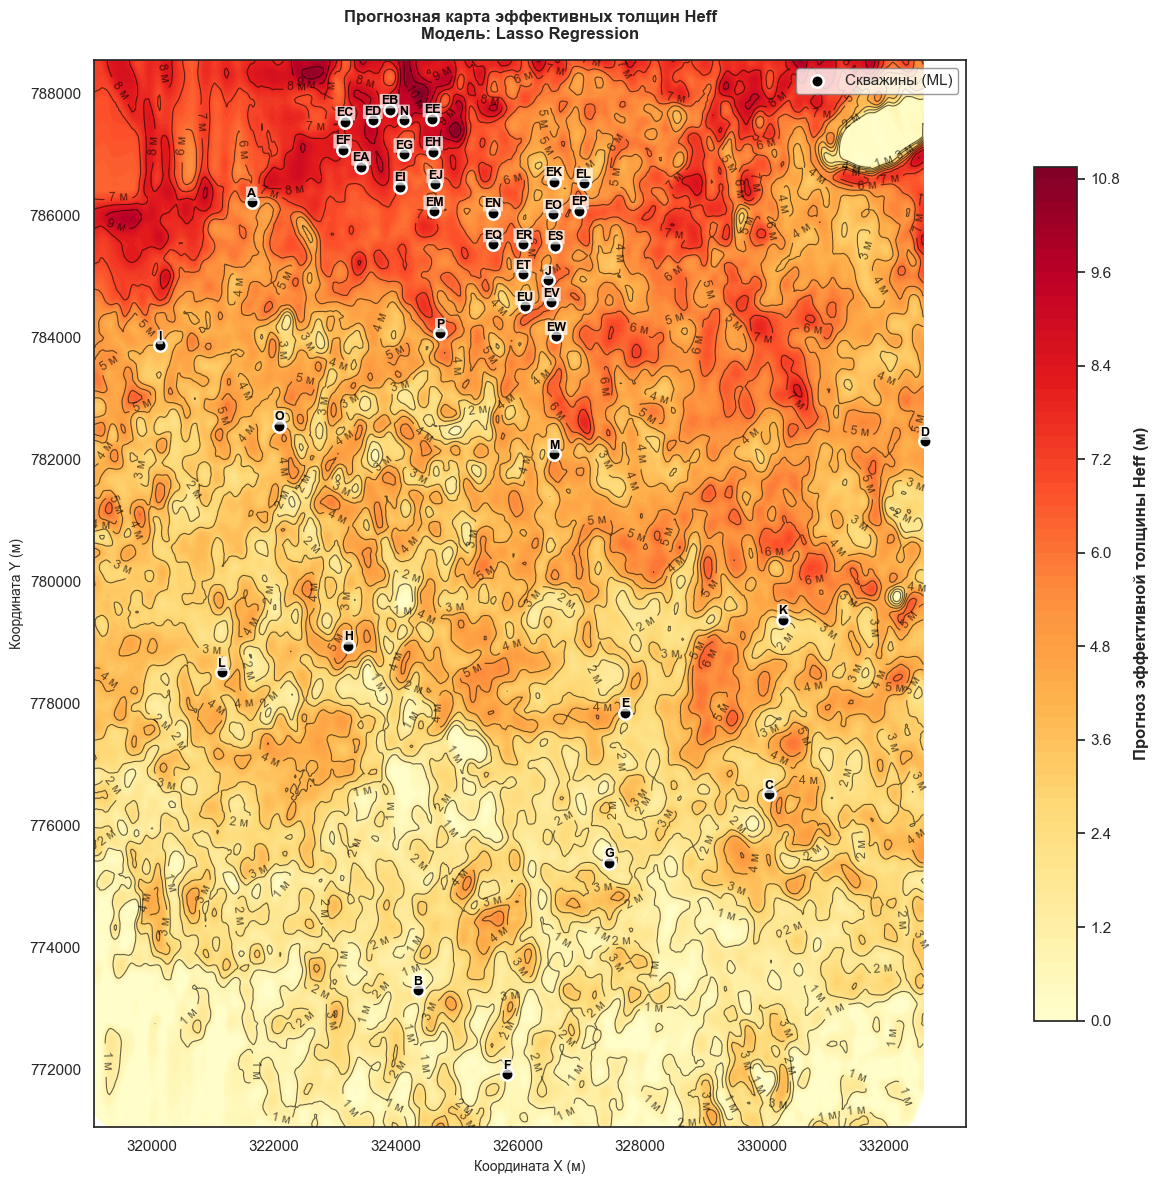

In [33]:
build_prediction_map(
        best_lasso_model=lasso_grid.best_estimator_, 
         trained_scaler=scaler, 
         feature_columns=list(X_train.columns), 
         data_slices_dir='./DATA_SLICES/',
         output_txt='predicted_heff_map.txt'
    )
